# CSC 413 Robotics — Assignment 1: Motor Parameter Identification

**Student:** Nilufarxon Ibrohimjonova 
**Student ID:** 240026  
**Robot:** TRIK, drive motors M3 and M4

This notebook contains the report and analysis of the motor experiments. The code uses the original data files from the `motor_data/` folder.

| File | Description |
|---|---|
| `steps_M4.txt`, `steps_M4_run2.txt` | Step-response measurements for motor M4 (two runs) |
| `steps_M3.txt` | Step-response measurements for motor M3 |
| `signal_M4.txt`, `signal_M3.txt` | Triangle-signal measurements for M4 and M3 |
| `battery.txt` | Battery voltage before and after each run |

Each row contains `angle, time, PWM` (encoder angle in degrees, time in milliseconds, and PWM in percent).

---

## 1. Motor model

For a DC motor with a small load, we can approximate its speed response with a first-order model. In this model, the armature inductance is ignored:

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega$$

| Symbol | Meaning | Unit |
|---|---|---|
| $U$ | Voltage supplied to the motor. The TRIK controller uses PWM, so $U = \text{PWM}/100 \cdot U_{battery}$ | V |
| $\theta,\ \omega$ | Wheel angle and angular speed | rad, rad/s |
| $\omega_{ss}$ | Speed reached after the motor has had enough time to respond to a constant input | rad/s |
| $T_m$ | Time constant. The motor reaches about 63% of its final speed after this time | s |
| $k_e$ | Back-EMF constant, which relates motor speed to voltage | V·s/rad |

### Deriving the angle response

For a step input, the voltage is constant and the motor starts from rest: $\omega(0)=0$ and $\theta(0)=0$. Let $\omega_{ss}=U/k_e$.

1. Rewrite the equation as $\dfrac{d\omega}{dt}=\dfrac{\omega_{ss}-\omega}{T_m}$.
2. Separate the variables: $\dfrac{d\omega}{\omega_{ss}-\omega}=\dfrac{dt}{T_m}$.
3. Integrate: $-\ln(\omega_{ss}-\omega)=\dfrac{t}{T_m}+C$. Using the initial condition gives $C=-\ln\omega_{ss}$.
4. Therefore, $\boxed{\omega(t)=\omega_{ss}(1-e^{-t/T_m})}$.
5. Integrating speed gives the angle:
   $$\theta(t)=\int_0^t \omega_{ss}(1-e^{-s/T_m})\,ds$$
6. After applying the limits:
   $$\boxed{\theta(t)=\omega_{ss}(t-T_m+T_m e^{-t/T_m})}$$

At $t=T_m$, the speed is about 63% of its final value. After a longer time, the angle curve becomes almost a straight line, and its slope is the steady-state speed.

### Assumptions

The model uses four simplifying assumptions:

1. **No inductance** — the motor current changes almost instantly, because the electrical time constant is much smaller than $T_m$.
2. **Linear viscous friction** — friction torque is proportional to speed, so $\omega_{ss}$ should be proportional to $U$ and the speed line should pass through zero.
3. **Constant load** — the wheels spin freely in the air and nothing changes the load during a run.
4. **Constant battery voltage within a run** — so the same PWM always means the same voltage.

Together these also mean that $T_m$ and $k_e$ should be the same at every PWM level. The measurements in the following sections show how well these assumptions fit the real motors.

---

## 2. Test signals and data collection

Two types of input signals were used in the experiment.

- **Step signal (Program A):** The motor was first kept off for 3 seconds to check encoder drift. Then the PWM was changed from -100% to -10% and from +10% to +100%, in steps of 10%. Each level lasted 3 seconds: 2 seconds with the motor powered and 1 second with the motor off to record coasting. The zero level was skipped.
- **Triangle signal (Program B):** The input was a triangle wave with amplitude 60%, period 2 seconds, and total duration 10 seconds. One additional second was recorded after the signal for the coasting period.

**Why use a triangle signal?** It changes gradually from negative to positive PWM and back again. This makes it possible to observe both rotation directions, the behaviour near zero PWM, and what happens when the motor changes direction. The 60% amplitude also keeps the motor away from its maximum input.

**Setup:** The same 5 ms Timer setting was used in the programs. The motor/encoder port and output file were changed for M3 and M4. The data files were downloaded from the robot without editing. The robot was lifted so that the wheels could spin freely without touching the floor, so the motors had no external load during the measurements.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import optimize
from scipy.integrate import odeint

# In Colab: upload the motor_data folder next to this notebook (or mount Google Drive and change DATA)
DATA = 'motor_data/'          # folder with the raw robot files
DEG2RAD = np.pi / 180         # TRIK encoder gives degrees
plt.rcParams['figure.dpi'] = 110

bat = pd.read_csv(DATA + 'battery.txt')
display(bat)
U_BAT = bat[['U_before', 'U_after']].values.mean()
print(f'U_battery used in the calculations = {U_BAT:.2f} V')

,file,U_before,U_after
0,steps_M4.txt,11.2,11.2
1,steps_M4_run2.txt,11.2,11.2
2,steps_M3.txt,11.2,11.2
3,signal_M4.txt,11.2,11.2
4,signal_M3.txt,11.2,11.2


U_battery used in the calculations = 11.20 V


## 3. Loading the data and converting units

The data columns are ordered as **angle, time, PWM**. I convert the encoder angle from degrees to radians and the time from milliseconds to seconds. PWM is kept as a percentage.

---

In [2]:
def load(name):
    d = np.loadtxt(DATA + name, delimiter=',')
    theta = d[:, 0] * DEG2RAD     # rad
    t     = d[:, 1] / 1000.0      # s
    pwm   = d[:, 2]               # %
    return theta, t, pwm

def split_segments(pwm):
    # list of (start, end, level) for every block of constant PWM
    edges = np.r_[0, np.flatnonzero(np.diff(pwm) != 0) + 1, len(pwm)]
    return [(edges[i], edges[i+1], pwm[edges[i]]) for i in range(len(edges) - 1)]

STEP_FILES = {'M4 run 1': 'steps_M4.txt', 'M4 run 2': 'steps_M4_run2.txt', 'M3': 'steps_M3.txt'}
steps = {k: load(f) for k, f in STEP_FILES.items()}
for k, (th, t, u) in steps.items():
    print(f'{k:9s}: {len(t)} samples, duration {t[-1]-t[0]:.1f} s, first time() = {t[0]*1000:.0f} ms')

M4 run 1 : 3219 samples, duration 63.2 s, first time() = 37 ms
M4 run 2 : 3252 samples, duration 63.2 s, first time() = 21 ms
M3       : 3238 samples, duration 63.2 s, first time() = 22 ms


## 4. Step responses — estimating $\omega_{ss}$ and $T_m$

For each section where PWM is not zero, I subtract the starting angle and starting time. Then I fit the first-order model from Section 1 using `curve_fit`.

I set a lower bound for $T_m$ of 5 ms. Without this limit, some fits at ±100% PWM gave values close to zero and caused numerical problems in the exponential calculation.

---

In [3]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def fit_steps(theta, t, pwm):
    rows = []
    for a, b, lvl in split_segments(pwm):
        if lvl == 0:
            continue
        ts  = t[a:b] - t[a]
        ths = theta[a:b] - theta[a]
        popt, pcov = optimize.curve_fit(model, ts, ths, p0=[np.sign(lvl) * 8, 0.1],
                                        bounds=([-50, 0.005], [50, 2]))
        err = np.sqrt(np.diag(pcov))
        rows.append(dict(PWM=int(lvl), w_ss=popt[0], w_err=err[0], T_m=popt[1], T_err=err[1]))
    return pd.DataFrame(rows)

fits = {k: fit_steps(*v) for k, v in steps.items()}
table = pd.concat({k: f.set_index('PWM') for k, f in fits.items()}, axis=1).round(4)
table

M4 run 1                         M4 run 2                          \
         w_ss   w_err     T_m   T_err     w_ss   w_err     T_m   T_err   
PWM                                                                      
-100 -13.7258  0.0030  0.0356  0.0003 -13.7285  0.0029  0.0317  0.0002   
-90  -12.4813  0.0037  0.0632  0.0003 -12.5548  0.0040  0.0607  0.0004   
-80  -11.4163  0.0033  0.0954  0.0003 -11.5729  0.0040  0.0939  0.0004   
-70  -10.2683  0.0088  0.0818  0.0010 -10.4671  0.0095  0.0839  0.0010   
-60   -9.2975  0.0035  0.1554  0.0004  -9.5022  0.0046  0.1534  0.0006   
-50   -8.4400  0.0032  0.1842  0.0004  -8.6784  0.0031  0.1754  0.0004   
-40   -7.6780  0.0129  0.0739  0.0020  -7.9637  0.0041  0.1874  0.0006   
-30   -6.3210  0.0049  0.2403  0.0009  -6.5319  0.0074  0.2446  0.0013   
-20   -4.9802  0.0041  0.2595  0.0010  -5.3370  0.0071  0.2561  0.0016   
-10   -3.4624  0.0061  0.2691  0.0021  -3.4625  0.0047  0.2573  0.0016   
 10    3.5560  0.0035  0.3021  0.0012   4.0543  0.0042  0.3606  0.0012   
 20    5.1486  0.0046  0.2495  0.0010   5.5984  0.0035  0.2658  0.0007   
 30    6.2430  0.0045  0.2163  0.0008   6.8428  0.0028  0.2375  0.0005   
 40    7.9396  0.0057  0.1840  0.0008   8.2660  0.0062  0.1866  0.0009   
 50    8.6972  0.0042  0.1718  0.0006   8.9751  0.0066  0.1791  0.0008   
 60    9.6371  0.0048  0.1618  0.0006   9.8408  0.0124  0.0854  0.0014   
 70   10.7283  0.0051  0.1276  0.0005  10.9125  0.0043  0.1266  0.0005   
 80   11.9520  0.0064  0.0795  0.0006  12.0845  0.0070  0.0725  0.0007   
 90   13.1595  0.0042  0.0632  0.0004  13.2640  0.0031  0.0678  0.0003   
 100  14.6198  0.0034  0.0341  0.0003  14.6415  0.0033  0.0317  0.0003   

           M3                          
         w_ss   w_err     T_m   T_err  
PWM                                    
-100 -14.5898  0.0032  0.0379  0.0002  
-90  -13.6212  0.0040  0.0792  0.0003  
-80  -12.6997  0.0053  0.1053  0.0005  
-70  -11.7533  0.0039  0.1579  0.0004  
-60  -10.7712  0.0073  0.1718  0.0008  
-50   -9.8642  0.0173  0.1056  0.0020  
-40   -9.2611  0.0057  0.2302  0.0007  
-30   -7.8444  0.0091  0.3026  0.0014  
-20   -6.4178  0.0113  0.0544  0.0020  
-10   -4.7262  0.0051  0.4244  0.0013  
 10    4.7837  0.0052  0.4282  0.0013  
 20    6.4289  0.0084  0.2933  0.0015  
 30    7.6886  0.0146  0.0742  0.0022  
 40    9.2170  0.0073  0.2248  0.0009  
 50    9.8079  0.0149  0.1040  0.0017  
 60   10.8516  0.0046  0.1875  0.0005  
 70   11.8193  0.0073  0.1351  0.0007  
 80   12.8701  0.0038  0.1122  0.0003  
 90   13.8219  0.0044  0.0748  0.0004  
 100  14.9028  0.0026  0.0442  0.0002

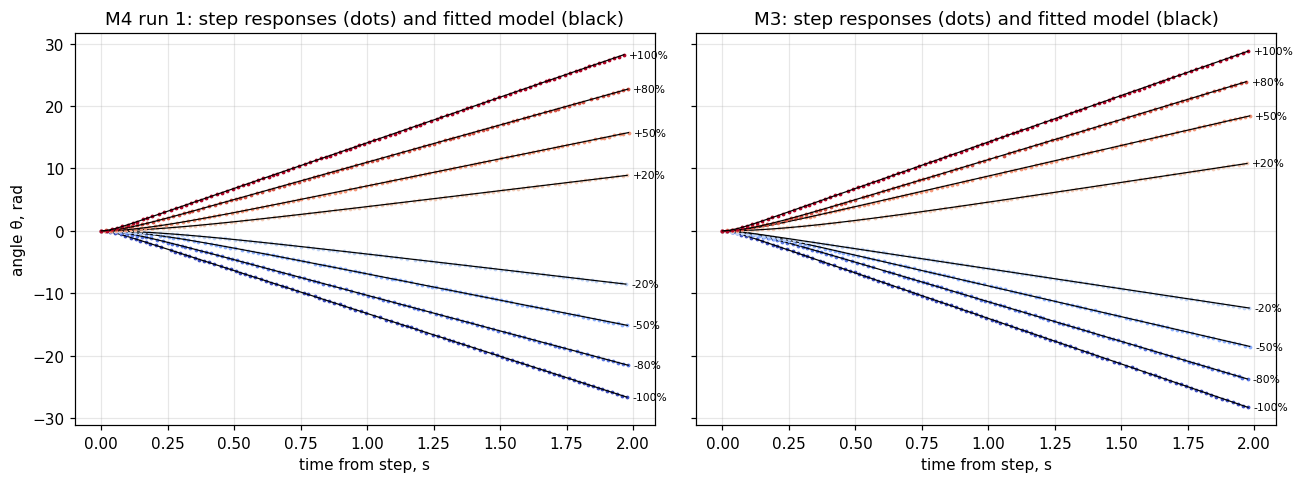

In [4]:
# Plot 1: step responses with the fitted model
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
show = [-100, -80, -50, -20, 20, 50, 80, 100]
cmap = plt.get_cmap('coolwarm')
for ax, key in zip(axes, ['M4 run 1', 'M3']):
    th, t, u = steps[key]
    f = fits[key].set_index('PWM')
    for a, b, lvl in split_segments(u):
        if lvl in show:
            ts, ths = t[a:b] - t[a], th[a:b] - th[a]
            c = cmap((lvl + 100) / 200)
            ax.plot(ts, ths, '.', ms=3, color=c)
            ax.plot(ts, model(ts, f.loc[lvl, 'w_ss'], f.loc[lvl, 'T_m']), '-', color='k', lw=0.8)
            ax.text(ts[-1] + 0.02, ths[-1], f'{int(lvl):+d}%', fontsize=7, va='center')
    ax.set_title(f'{key}: step responses (dots) and fitted model (black)')
    ax.set_xlabel('time from step, s'); ax.grid(alpha=.3)
axes[0].set_ylabel('angle θ, rad')
plt.tight_layout(); plt.show()

**Plot 1.** Measured angle values and the fitted first-order model for the step responses. The curves show a short acceleration period at the beginning, followed by an almost straight line. The slope of this line represents the steady-state speed, $\omega_{ss}$.



## 5. Speed and time constant versus PWM

I fit a straight line to the speed measurements between 10% and 80% PWM, treating forward and backward rotation separately:

$$\omega_{ss}=\text{slope}\cdot\text{PWM}+\text{offset}$$

The value of $k_e$ is then estimated from the slope using the battery voltage:

$$k_e=\dfrac{U_{bat}/100}{\text{slope}}$$

---

In [5]:
def line_fit(f, direction):
    m = (np.sign(f.PWM) == direction) & (f.PWM.abs() <= 80)
    slope, offset = np.polyfit(f.PWM[m], f.w_ss[m], 1)
    return slope, offset

summary = []
for key, f in fits.items():
    for d, name in [(1, 'Forward'), (-1, 'Backward')]:
        slope, offset = line_fit(f, d)
        Tm = f.T_m[np.sign(f.PWM) == d]
        summary.append({'Motor': key, 'Direction': name,
                        'Dead zone, % PWM': '< 10',
                        'Slope, rad/s per % PWM': round(slope, 4),
                        'Offset at 0 %, rad/s': round(offset, 2),
                        'k_e, V·s/rad': round(U_BAT / 100 / slope, 3),
                        'Mean T_m, s': round(Tm.mean(), 3),
                        'Std T_m, s': round(Tm.std(), 3),
                        'U_battery, V': U_BAT})
summary = pd.DataFrame(summary)
summary

,Motor,Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","Offset at 0 %, rad/s","k_e, V·s/rad","Mean T_m, s","Std T_m, s","U_battery, V"
0,M4 run 1,Forward,< 10,0.1162,2.76,0.964,0.159,0.085,11.2
1,M4 run 1,Backward,< 10,0.1093,-2.81,1.025,0.146,0.088,11.2
2,M4 run 2,Forward,< 10,0.1101,3.37,1.017,0.161,0.104,11.2
3,M4 run 2,Backward,< 10,0.1096,-3.01,1.022,0.154,0.084,11.2
4,M3,Forward,< 10,0.1115,4.17,1.005,0.168,0.119,11.2
5,M3,Backward,< 10,0.1094,-4.25,1.024,0.167,0.122,11.2


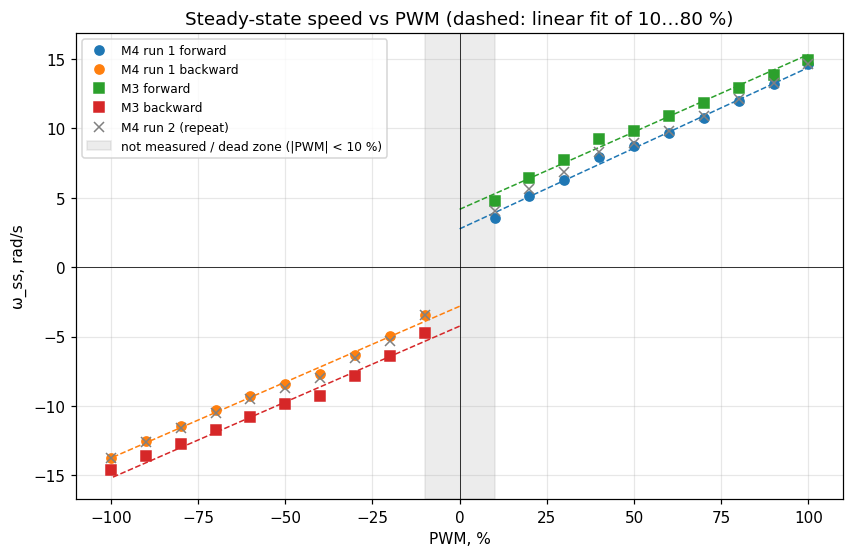

In [6]:
# Plot 2: speed from PWM
styles = {'M4 run 1': ('tab:blue', 'tab:orange', 'o'), 'M3': ('tab:green', 'tab:red', 's')}
fig, ax = plt.subplots(figsize=(9, 5.5))
for key, (cf, cb, mk) in styles.items():
    f = fits[key]
    for d, c, name in [(1, cf, 'forward'), (-1, cb, 'backward')]:
        s = f[np.sign(f.PWM) == d]
        ax.plot(s.PWM, s.w_ss, mk, color=c, label=f'{key} {name}')
        slope, offset = line_fit(f, d)
        x = np.linspace(0, d * 100, 50)
        ax.plot(x, slope * x + offset, '--', color=c, lw=1)
f2 = fits['M4 run 2']
ax.plot(f2.PWM, f2.w_ss, 'x', color='gray', label='M4 run 2 (repeat)')
ax.axvspan(-10, 10, color='gray', alpha=.15, label='not measured / dead zone (|PWM| < 10 %)')
ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
ax.set_xlabel('PWM, %'); ax.set_ylabel('ω_ss, rad/s'); ax.grid(alpha=.3)
ax.set_title('Steady-state speed vs PWM (dashed: linear fit of 10…80 %)')
ax.legend(fontsize=8); plt.show()

**Plot 2.** Steady-state speed versus PWM. The measurements are close to linear, but the fitted lines do not pass through zero. There is an offset of about 3 rad/s for M4 and 4 rad/s for M3. Even at 10% PWM, both motors are already rotating at around 3.5–4.8 rad/s. This means the dead zone is below 10%, so it cannot be measured precisely with the step sizes used here. I use 5% as an estimate in the simulation.



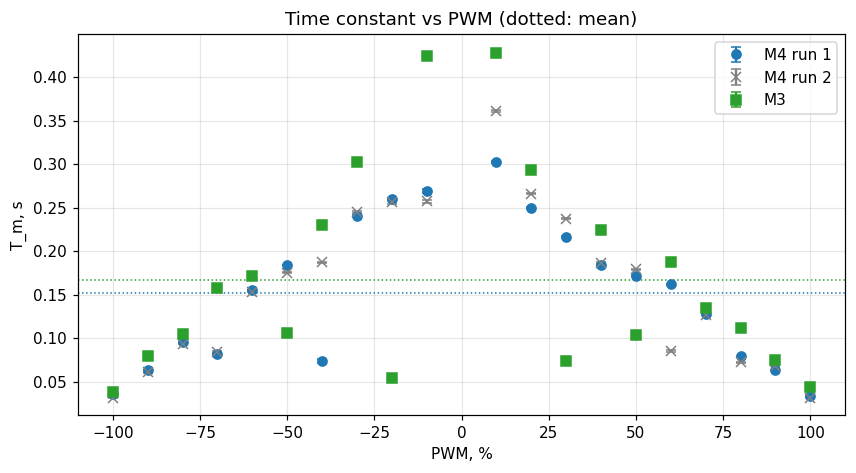

Typical standard error of T_m: 0.0007 s


In [7]:
# Plot 3: T_m from PWM with error bars
fig, ax = plt.subplots(figsize=(9, 4.5))
for key, c, mk in [('M4 run 1', 'tab:blue', 'o'), ('M4 run 2', 'gray', 'x'), ('M3', 'tab:green', 's')]:
    f = fits[key]
    ax.errorbar(f.PWM, f.T_m, yerr=f.T_err, fmt=mk, color=c, capsize=3, label=key)
for key, c in [('M4 run 1', 'tab:blue'), ('M3', 'tab:green')]:
    ax.axhline(fits[key].T_m.mean(), color=c, ls=':', lw=1)
ax.set_xlabel('PWM, %'); ax.set_ylabel('T_m, s'); ax.grid(alpha=.3); ax.legend()
ax.set_title('Time constant vs PWM (dotted: mean)'); plt.show()

print('Typical standard error of T_m:', round(pd.concat(fits.values()).T_err.median(), 4), 's')

**Plot 3. Is $T_m$ constant?** The results show that it changes with PWM. It is around 0.25–0.43 s at ±10%, 0.1–0.18 s at ±50%, and 0.03–0.04 s at ±100%. The small fit error bars suggest that this change is not only caused by fitting noise. One possible reason is friction and the motor driver's behaviour at low PWM. At high PWM, the time constant is close to the sampling interval, so there are only a few samples during acceleration. Those estimates are therefore less reliable. Some individual points also differ from nearby values, which is why I compare the median values at each PWM level as well.



## 6. Complex signal: comparing the models with the real motor

I simulate the motor response with `odeint`, using the recorded PWM values as the input and converting them to voltage.

- **Model A — basic model:** Uses the first-order equation directly. Its steady-state speed is proportional to voltage and the line passes through zero.
- **Model B — dead zone and offset:** Treats PWM values within ±5% as zero. Outside this range, it uses the forward or backward speed line from Plot 2. The time constant is kept constant.
- **Model C — PWM-dependent time constant:** Uses the same dead-zone and offset approach as Model B, but changes $T_m$ according to the median values measured at different PWM levels in Plot 3.

The measured speed is calculated from the angle using `np.gradient(θ, t)` and then smoothed with a centred moving average of 5 samples (about 130 ms).

---

In [8]:
DZ = 5.0   # dead zone, % PWM

def params(key):
    f = fits[key]
    sf, of = line_fit(f, 1)
    sb, ob = line_fit(f, -1)
    return dict(ke=U_BAT / 100 / ((sf + sb) / 2),  ke_f=U_BAT / 100 / sf, ke_b=U_BAT / 100 / sb,
                off_f=of, off_b=-ob, T_m=f.T_m.mean(),
                levels=np.arange(10, 101, 10),
                Tm_med=[f.T_m[f.PWM.abs() == L].median() for L in range(10, 101, 10)])

def simulate(t_log, pwm_log, p, dead_zone, Tm_varies=False):
    U_log = pwm_log / 100 * U_BAT                 # recorded input in volts
    def motor(state, t):
        speed, angle = state
        U = np.interp(t, t_log, U_log)
        pwm = U / U_BAT * 100
        if not dead_zone:                         # Model A
            w_target = U / p['ke']
        elif abs(pwm) <= DZ:                      # Model B, inside dead zone
            w_target = 0.0
        elif U > 0:                               # Model B, forward
            w_target = p['off_f'] + U / p['ke_f']
        else:                                     # Model B, backward
            w_target = -p['off_b'] + U / p['ke_b']
        T_m = np.interp(abs(pwm), p['levels'], p['Tm_med']) if Tm_varies else p['T_m']   # Model C
        return np.array([-speed / T_m + w_target / T_m, speed])
    y = odeint(motor, [0, 0], t_log, hmax=0.005)
    return y[:, 0], y[:, 1]                       # speed, angle

def smooth(x, n=5):
    return np.convolve(x, np.ones(n) / n, mode='same')

def fit_percent(y, yh):
    return 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - y.mean()))

sig = {}
results = []
for motor_name, step_key in [('M4', 'M4 run 1'), ('M3', 'M3')]:
    th, t, u = load(f'signal_{motor_name}.txt')
    th, t = th - th[0], t - t[0]
    w_meas = smooth(np.gradient(th, t))
    p = params(step_key)
    out = dict(t=t, th=th, u=u, w=w_meas, p=p)
    names = {'A': 'A: no dead zone', 'B': 'B: dead zone + offset', 'C': 'C: B + T_m(PWM)'}
    for label, dzflag, tmflag in [('A', False, False), ('B', True, False), ('C', True, True)]:
        w_sim, th_sim = simulate(t, u, p, dzflag, tmflag)
        out['w_' + label], out['th_' + label] = w_sim, th_sim
        results.append({'Motor': motor_name, 'Model': names[label],
                        'Angle RMSE, rad': np.sqrt(np.mean((th - th_sim)**2)),
                        'Angle fit, %': fit_percent(th, th_sim),
                        'Speed RMSE, rad/s': np.sqrt(np.mean((w_meas - w_sim)**2)),
                        'Speed fit, %': fit_percent(w_meas, w_sim)})
    sig[motor_name] = out
pd.DataFrame(results).round(2)

,Motor,Model,"Angle RMSE, rad","Angle fit, %","Speed RMSE, rad/s","Speed fit, %"
0,M4,A: no dead zone,0.90,50.30,2.38,55.98
1,M4,B: dead zone + offset,0.38,79.01,1.01,81.33
2,M4,C: B + T_m(PWM),0.36,79.90,0.86,84.10
3,M3,A: no dead zone,1.04,45.42,3.01,49.31
4,M3,B: dead zone + offset,0.57,70.14,1.35,77.30
5,M3,C: B + T_m(PWM),0.47,75.44,0.89,84.95


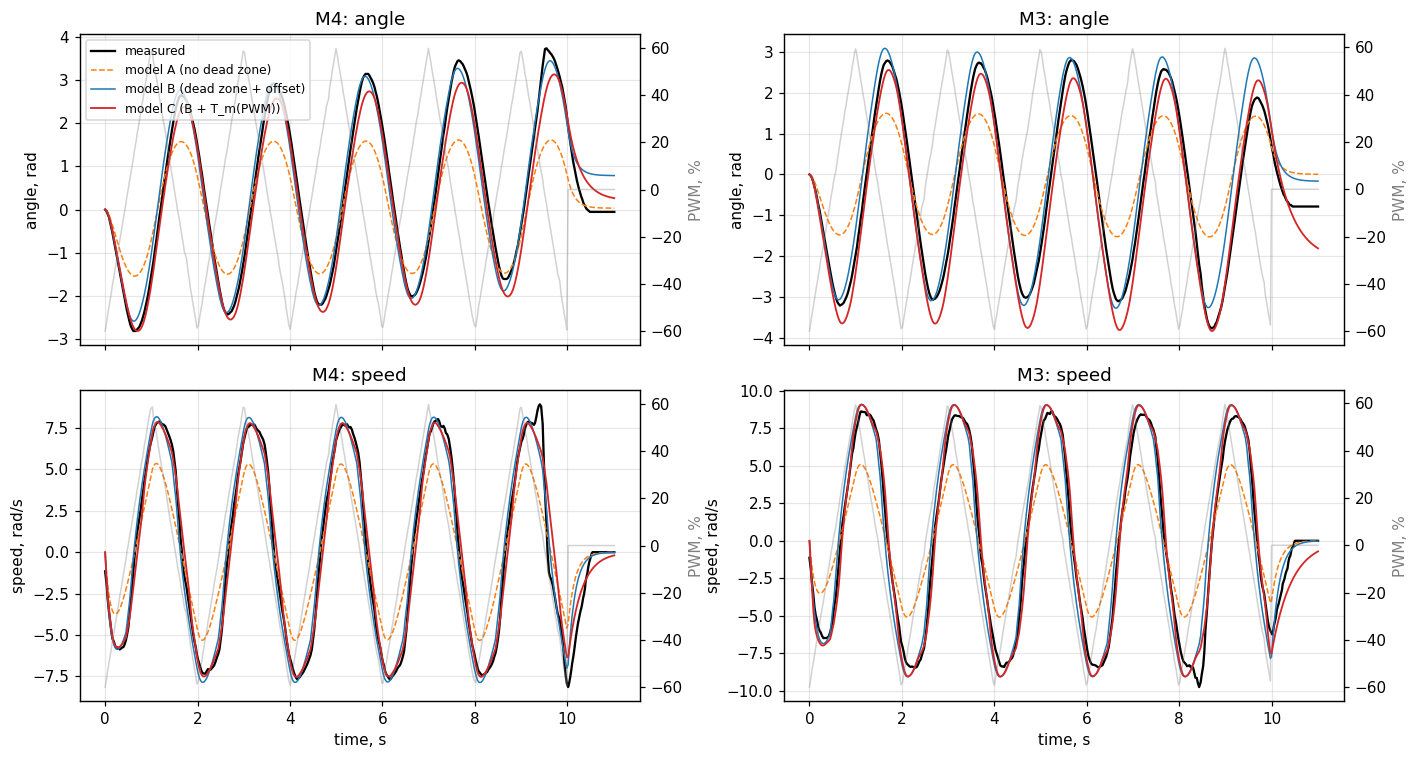

In [9]:
# Plot 4: measured vs simulated angle and speed, with PWM on a second axis
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for col, m in enumerate(['M4', 'M3']):
    s = sig[m]
    for row, (meas, a, b, cc, ylab) in enumerate([(s['th'], s['th_A'], s['th_B'], s['th_C'], 'angle, rad'),
                                                   (s['w'], s['w_A'], s['w_B'], s['w_C'], 'speed, rad/s')]):
        ax = axes[row, col]
        ax.plot(s['t'], meas, 'k', lw=1.5, label='measured')
        ax.plot(s['t'], a, 'tab:orange', lw=1, ls='--', label='model A (no dead zone)')
        ax.plot(s['t'], b, 'tab:blue', lw=1, label='model B (dead zone + offset)')
        ax.plot(s['t'], cc, 'tab:red', lw=1.2, label='model C (B + T_m(PWM))')
        ax2 = ax.twinx(); ax2.plot(s['t'], s['u'], color='gray', alpha=.35, lw=1); ax2.set_ylabel('PWM, %', color='gray')
        ax.set_ylabel(ylab); ax.grid(alpha=.3); ax.set_title(f'{m}: {ylab.split(",")[0]}')
    axes[1, col].set_xlabel('time, s')
axes[0, 0].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()

**Plot 4.** Comparison of the measured motor response with the three simulated models. Model A does not match the motor as well, especially at low and medium PWM, because it does not include the speed offset seen in the measurements. Models B and C are closer to the measured speed. Model C gives a slightly better result around zero PWM, where the motor has a longer time constant. Small speed errors also accumulate over time, which explains the difference in angle.



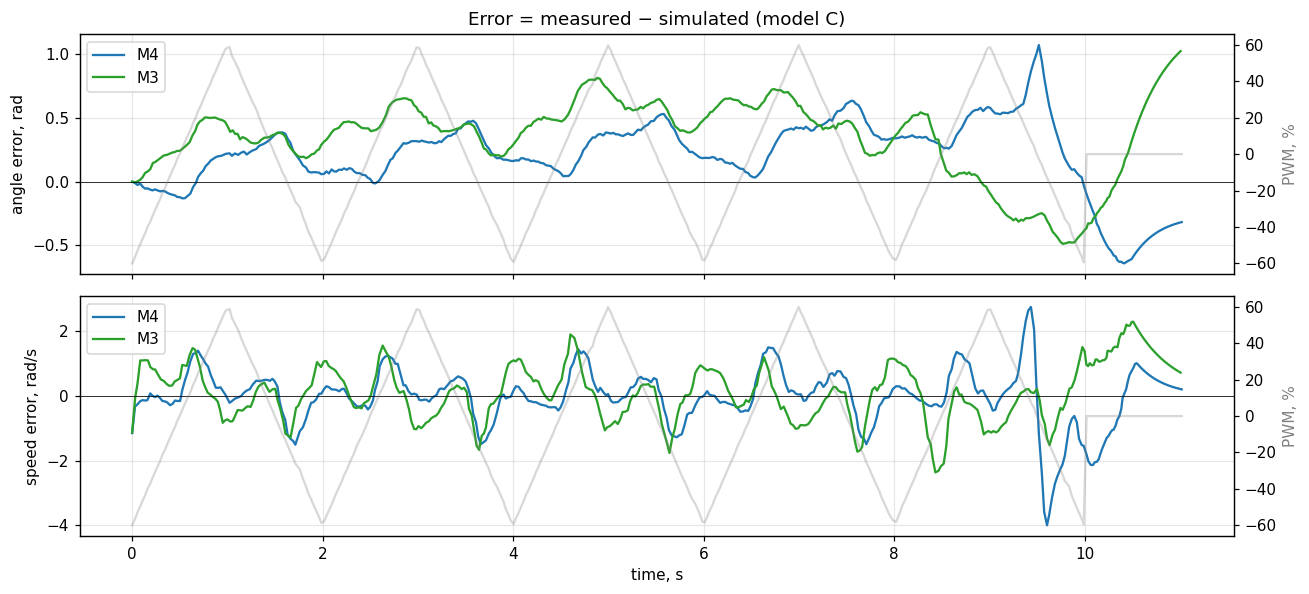

M4: mean |speed error| near zero crossings (|PWM|<20%) = 0.76 rad/s, elsewhere = 0.47 rad/s
M3: mean |speed error| near zero crossings (|PWM|<20%) = 0.90 rad/s, elsewhere = 0.59 rad/s


In [10]:
# Plot 5: error (measured - simulated, best model C) over time
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for m, c in [('M4', 'tab:blue'), ('M3', 'tab:green')]:
    s = sig[m]
    axes[0].plot(s['t'], s['th'] - s['th_C'], c, label=m)
    axes[1].plot(s['t'], s['w'] - s['w_C'], c, label=m)
for ax in axes:
    ax2 = ax.twinx(); ax2.plot(sig['M4']['t'], sig['M4']['u'], color='gray', alpha=.3); ax2.set_ylabel('PWM, %', color='gray')
    ax.axhline(0, color='k', lw=.5); ax.grid(alpha=.3); ax.legend(loc='upper left')
axes[0].set_ylabel('angle error, rad'); axes[1].set_ylabel('speed error, rad/s'); axes[1].set_xlabel('time, s')
axes[0].set_title('Error = measured − simulated (model C)')
plt.tight_layout(); plt.show()

for m in ['M4', 'M3']:
    s = sig[m]; e = np.abs(s['w'] - s['w_C'])
    near0 = np.abs(s['u']) < 20
    print(f"{m}: mean |speed error| near zero crossings (|PWM|<20%) = {e[near0].mean():.2f} rad/s, elsewhere = {e[~near0].mean():.2f} rad/s")

**Plot 5.** The speed error is mostly within ±1.5 rad/s. It becomes larger around zero crossings, where the dead zone, start-up behaviour, backlash, and changing time constant have more influence. There is also a large jump in the M4 measurement at about 9.5 seconds that the models do not reproduce. It may be caused by an irregular sample in the recording. During coasting, the error increases again because the motor does not slow down exactly as predicted by the model. The angle error changes gradually and reaches about 1 rad.



## 7. Other effects visible in the measurements



In [11]:
# 7.1 Forward vs backward asymmetry (%)
rows = []
for key in ['M4 run 1', 'M4 run 2', 'M3']:
    s = summary[summary.Motor == key].set_index('Direction')
    f = fits[key].set_index('PWM')
    w_f = f.loc[[10, 50, 90], 'w_ss'].values; w_b = -f.loc[[-10, -50, -90], 'w_ss'].values
    pct = lambda a, b: 100 * (a - b) / ((a + b) / 2)
    rows.append({'Motor': key,
                 'slope fwd vs bwd, %': pct(s.loc['Forward', 'Slope, rad/s per % PWM'], s.loc['Backward', 'Slope, rad/s per % PWM']),
                 'offset fwd vs bwd, %': pct(s.loc['Forward', 'Offset at 0 %, rad/s'], -s.loc['Backward', 'Offset at 0 %, rad/s']),
                 'mean T_m fwd vs bwd, %': pct(s.loc['Forward', 'Mean T_m, s'], s.loc['Backward', 'Mean T_m, s']),
                 'ω at ±10 %, %': pct(w_f[0], w_b[0]), 'ω at ±50 %, %': pct(w_f[1], w_b[1]), 'ω at ±90 %, %': pct(w_f[2], w_b[2])})
pd.DataFrame(rows).round(1)

,Motor,"slope fwd vs bwd, %","offset fwd vs bwd, %","mean T_m fwd vs bwd, %","ω at ±10 %, %","ω at ±50 %, %","ω at ±90 %, %"
0,M4 run 1,6.1,-1.8,8.5,2.7,3.0,5.3
1,M4 run 2,0.5,11.3,4.4,15.7,3.4,5.5
2,M3,1.9,-1.9,0.6,1.2,-0.6,1.5


M4 run 1: encoder change in 3 s with motor off = 0°, first time() = 37 ms, final angle after series = 352°
M4 run 2: encoder change in 3 s with motor off = 0°, first time() = 21 ms, final angle after series = 461°
M3: encoder change in 3 s with motor off = 0°, first time() = 22 ms, final angle after series = 175°


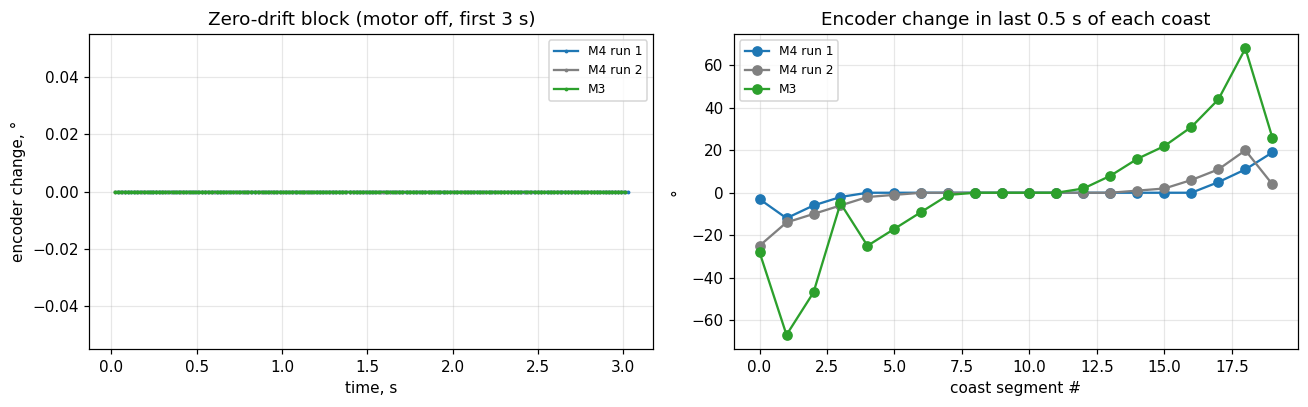

In [12]:
# 7.2 Zero drift: first 3 s with motor off + the rest periods at the end of each coasting segment
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for key, c in [('M4 run 1', 'tab:blue'), ('M4 run 2', 'gray'), ('M3', 'tab:green')]:
    th, t, u = steps[key]
    a, b, lvl = split_segments(u)[0]
    axes[0].plot(t[a:b], (th[a:b] - th[a]) / DEG2RAD, '.-', color=c, ms=3, label=key)
    # change of the encoder during the last 0.5 s of every coasting segment
    drift = []
    for a2, b2, l2 in split_segments(u)[1:]:
        if l2 == 0:
            m = t[a2:b2] > t[b2 - 1] - 0.5
            drift.append((th[a2:b2][m][-1] - th[a2:b2][m][0]) / DEG2RAD)
    axes[1].plot(drift, 'o-', color=c, label=key)
    print(f'{key}: encoder change in 3 s with motor off = {(th[b-1]-th[a])/DEG2RAD:.0f}°, '
          f'first time() = {t[0]*1000:.0f} ms, final angle after series = {th[-1]/DEG2RAD:.0f}°')
axes[0].set_title('Zero-drift block (motor off, first 3 s)'); axes[0].set_xlabel('time, s'); axes[0].set_ylabel('encoder change, °')
axes[1].set_title('Encoder change in last 0.5 s of each coast'); axes[1].set_xlabel('coast segment #'); axes[1].set_ylabel('°')
for ax in axes: ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Zero drift.** While the motor was off, the encoder reading stayed unchanged during the initial 3 seconds in all runs. The wheel also stopped by the end of the coasting periods, with a change of at most about one encoder tick. The final angle after a full step series is not zero, but this is due to the total forward and backward movement, not encoder drift. The first recorded time value is between 21 and 37 ms rather than exactly zero, so I shift the time of each segment to start at zero.



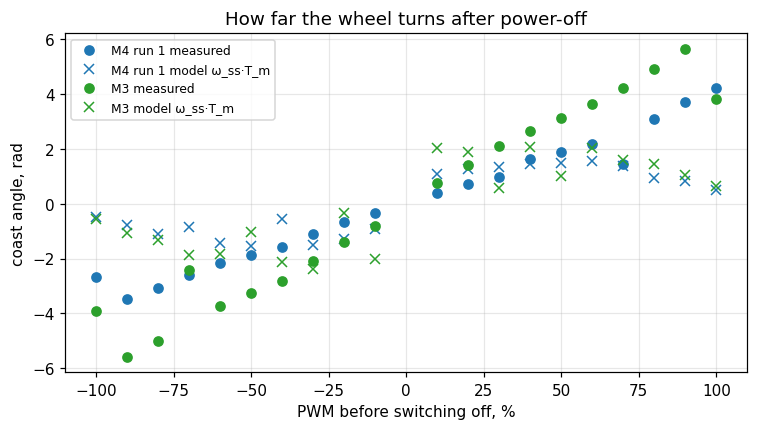

Mean ratio measured / model: 2.6


In [13]:
# 7.3 Coasting after power-off: measured coast angle vs first-order model prediction ω_ss·T_m
rows = []
for key in ['M4 run 1', 'M3']:
    th, t, u = steps[key]
    f = fits[key].set_index('PWM')
    segs = split_segments(u)
    for i in range(1, len(segs)):
        a, b, lvl = segs[i]
        prev = segs[i - 1][2]
        if lvl == 0 and prev != 0:
            rows.append({'Motor': key, 'PWM before': int(prev), 'coast, rad': th[b - 1] - th[a],
                         'model ω_ss·T_m, rad': f.loc[prev, 'w_ss'] * f.loc[prev, 'T_m']})
coast = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
for key, c in [('M4 run 1', 'tab:blue'), ('M3', 'tab:green')]:
    s = coast[coast.Motor == key]
    ax.plot(s['PWM before'], s['coast, rad'], 'o', color=c, label=f'{key} measured')
    ax.plot(s['PWM before'], s['model ω_ss·T_m, rad'], 'x', color=c, label=f'{key} model ω_ss·T_m')
ax.set_xlabel('PWM before switching off, %'); ax.set_ylabel('coast angle, rad'); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title('How far the wheel turns after power-off'); plt.show()
print('Mean ratio measured / model:', round((coast['coast, rad'] / coast['model ω_ss·T_m, rad']).mean(), 1))

**Coasting.** After the power is switched off, the wheel continues to rotate by about 0.3–5.7 rad. This is sometimes much more than the first-order model predicts. At higher PWM, the measured coast angle can be several times larger than the prediction. One possible explanation is that the motor is free-wheeling when the TRIK controller sets its power to zero. In that case, the motor is not actively braking, and friction is what brings the wheel to a stop. The coasting distance also varies between measurements.



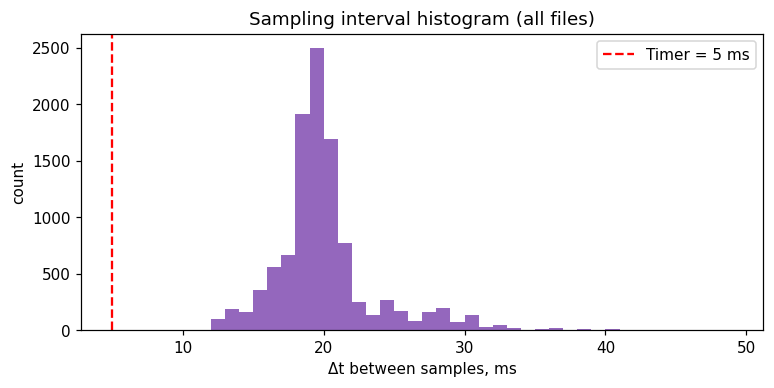

M4 run 1 : mean 19.6 ms, min 13, max 46
M4 run 2 : mean 19.4 ms, min 12, max 43
M3       : mean 19.5 ms, min 12, max 47
signal M4: mean 26.4 ms, min 14, max 47
signal M3: mean 26.4 ms, min 13, max 48


In [14]:
# 7.4 Sampling jitter
all_dt = np.concatenate([np.diff(steps[k][1]) for k in steps] + [np.diff(sig[m]['t']) for m in sig]) * 1000
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(all_dt, bins=np.arange(10, 50, 1), color='tab:purple')
ax.axvline(5, color='r', ls='--', label='Timer = 5 ms'); ax.legend()
ax.set_xlabel('Δt between samples, ms'); ax.set_ylabel('count'); ax.set_title('Sampling interval histogram (all files)')
plt.show()
for k in steps:
    d = np.diff(steps[k][1]) * 1000
    print(f'{k:9s}: mean {d.mean():.1f} ms, min {d.min():.0f}, max {d.max():.0f}')
for m in sig:
    d = np.diff(sig[m]['t']) * 1000
    print(f'signal {m}: mean {d.mean():.1f} ms, min {d.min():.0f}, max {d.max():.0f}')

**Sampling jitter.** Although the Timer setting is 5 ms, the measured time between samples is around 20 ms in the step programs and 26 ms in the signal program. The interval ranges from about 12 to 47 ms. Saving data takes time, so the actual sampling interval is not constant. This affects the estimates because the acceleration period may contain only a small number of samples. It is important to use the recorded time values instead of assuming every sample is exactly 5 ms apart.



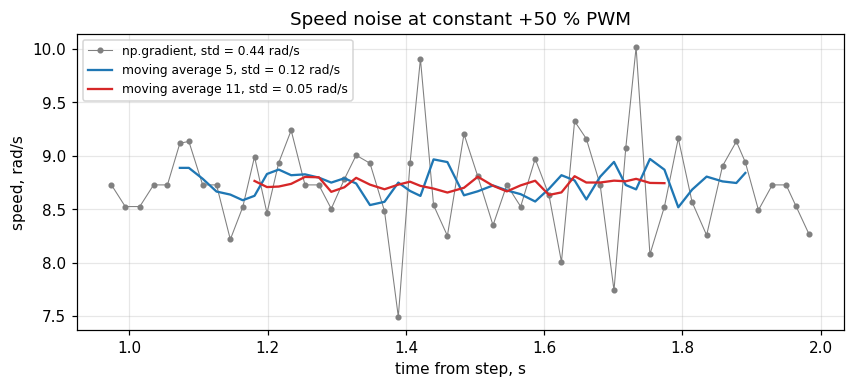

One encoder tick (1°) over one mean sample interval = 0.89 rad/s


In [15]:
# 7.5 Encoder quantisation and differentiation noise (steady part of the +50 % step, M4 run 1)
th, t, u = steps['M4 run 1']
a, b, _ = [s for s in split_segments(u) if s[2] == 50][0]
m = slice(a + 50, b)          # last ~1 s, motor at steady speed
w_raw = np.gradient(th[m], t[m])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(t[m] - t[a], w_raw, '.-', color='gray', lw=.7, label=f'np.gradient, std = {w_raw.std():.2f} rad/s')
for n, c in [(5, 'tab:blue'), (11, 'tab:red')]:
    ws = smooth(w_raw, n)[n:-n]
    ax.plot((t[m] - t[a])[n:-n], ws, color=c, label=f'moving average {n}, std = {ws.std():.2f} rad/s')
ax.set_xlabel('time from step, s'); ax.set_ylabel('speed, rad/s'); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title('Speed noise at constant +50 % PWM'); plt.show()
print(f'One encoder tick (1°) over one mean sample interval = {DEG2RAD/np.diff(t).mean():.2f} rad/s')

**Quantisation and differentiation noise.** The encoder measures whole degrees. With a time interval of about 20 ms, even a one-degree change can produce a noticeable difference in the calculated speed. As a result, the raw speed from `np.gradient` is noisy. A moving average reduces this noise, but using too many samples would also smooth out real changes in speed. I use a 5-sample window for the comparison.



M4: 8 reversals, wheel stopped for 57 ms on average (min 32, max 79)
M3: 5 reversals, wheel stopped for 54 ms on average (min 26, max 79)


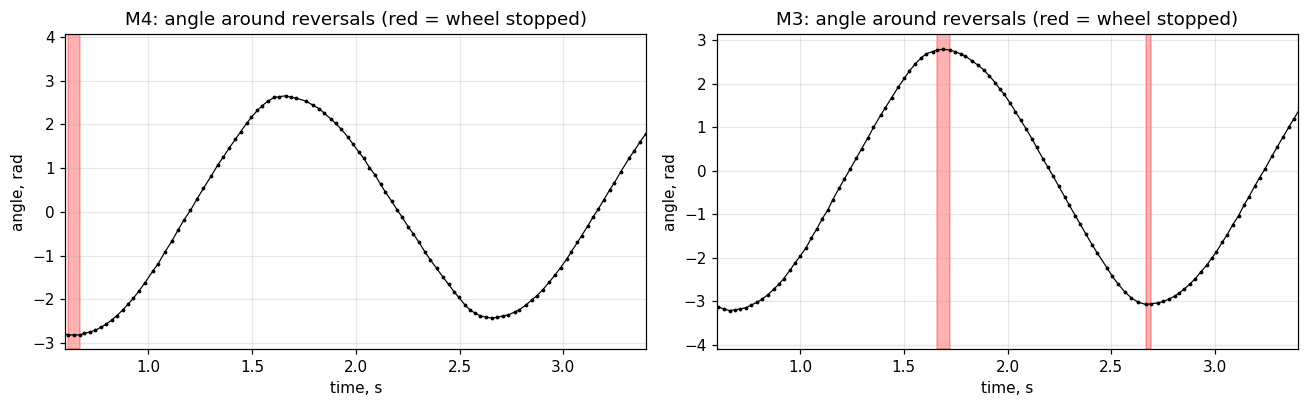

In [16]:
# 7.6 Gear backlash / flat region at reversals of the triangle
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, ['M4', 'M3']):
    s = sig[m]
    dth = np.diff(s['th']) / DEG2RAD
    w_sign = np.sign(np.round(dth))
    rev = np.flatnonzero((w_sign[:-1] != 0) & (np.r_[w_sign[1:]] == 0))   # start of a flat part
    flats = []
    i = 0
    while i < len(dth):           # length (ms) of each run of samples with |Δθ| <= 1° and sign change around it
        if abs(dth[i]) <= 1:
            j = i
            while j < len(dth) and abs(dth[j]) <= 1: j += 1
            if 0 < i and j < len(dth) and np.sign(dth[i-1]) != np.sign(dth[j]) and s['t'][-1] - s['t'][j] > 1.1:
                flats.append((s['t'][i], (s['t'][j] - s['t'][i]) * 1000))
            i = j
        else:
            i += 1
    for tf, dur in flats:
        ax.axvspan(tf, tf + dur / 1000, color='r', alpha=.3)
    ax.plot(s['t'], s['th'], 'k.-', ms=3, lw=.8)
    ax.set_xlim(0.6, 3.4); ax.set_title(f'{m}: angle around reversals (red = wheel stopped)')
    ax.set_xlabel('time, s'); ax.set_ylabel('angle, rad'); ax.grid(alpha=.3)
    d = [x[1] for x in flats]
    print(f'{m}: {len(d)} reversals, wheel stopped for {np.mean(d):.0f} ms on average (min {min(d):.0f}, max {max(d):.0f})')
plt.tight_layout(); plt.show()

**Backlash at reversals.** Around each change of direction, the angle sometimes stays almost constant for a short time. This can happen because of backlash in the gearbox: the gears need to move across a small gap before the wheel starts turning in the opposite direction. The dead zone may also contribute. In these measurements, the flat part lasts about 55 ms on average and can reach around 80 ms.



In [17]:
# 7.7 Battery sag and repeatability (same level, run 1 vs run 2 of M4)
r1 = fits['M4 run 1'].set_index('PWM'); r2 = fits['M4 run 2'].set_index('PWM')
rep = pd.DataFrame({'ω run1': r1.w_ss, 'ω run2': r2.w_ss,
                    'Δω, %': 100 * (r2.w_ss - r1.w_ss) / r1.w_ss.abs(),
                    'T_m run1': r1.T_m, 'T_m run2': r2.T_m}).round(3)
display(bat)
print(f'Mean |Δω| between run 1 and run 2: {rep["Δω, %"].abs().mean():.1f} %  (max {rep["Δω, %"].abs().max():.1f} %)')
rep.T

,file,U_before,U_after
0,steps_M4.txt,11.2,11.2
1,steps_M4_run2.txt,11.2,11.2
2,steps_M3.txt,11.2,11.2
3,signal_M4.txt,11.2,11.2
4,signal_M3.txt,11.2,11.2


Mean |Δω| between run 1 and run 2: 3.4 %  (max 14.0 %)


PWM,-100,-90,-80,-70,-60,-50,-40,-30,-20,-10,10,20,30,40,50,60,70,80,90,100
ω run1,-13.726,-12.481,-11.416,-10.268,-9.297,-8.440,-7.678,-6.321,-4.980,-3.462,3.556,5.149,6.243,7.940,8.697,9.637,10.728,11.952,13.159,14.620
ω run2,-13.729,-12.555,-11.573,-10.467,-9.502,-8.678,-7.964,-6.532,-5.337,-3.463,4.054,5.598,6.843,8.266,8.975,9.841,10.912,12.085,13.264,14.642
"Δω, %",-0.020,-0.588,-1.372,-1.937,-2.201,-2.824,-3.720,-3.337,-7.165,-0.005,14.011,8.736,9.607,4.112,3.195,2.114,1.716,1.108,0.794,0.149
T_m run1,0.036,0.063,0.095,0.082,0.155,0.184,0.074,0.240,0.260,0.269,0.302,0.249,0.216,0.184,0.172,0.162,0.128,0.079,0.063,0.034
T_m run2,0.032,0.061,0.094,0.084,0.153,0.175,0.187,0.245,0.256,0.257,0.361,0.266,0.238,0.187,0.179,0.085,0.127,0.073,0.068,0.032


**Battery voltage.** The battery reading was 11.2 V before and after each run, so any voltage drop was smaller than the display resolution of 0.1 V. The repeated M4 measurements still show some differences in speed, especially at low PWM. Since the second run was slightly faster rather than slower, battery voltage does not seem to explain this variation. Friction or gearbox temperature may also affect the results.



In [18]:
# 7.8 Motor-to-motor spread (M3 vs M4)
s = summary.set_index(['Motor', 'Direction'])
cols = ['Slope, rad/s per % PWM', 'Offset at 0 %, rad/s', 'k_e, V·s/rad', 'Mean T_m, s']
spread = pd.DataFrame({d: 100 * (s.loc[('M3', d), cols] - s.loc[('M4 run 1', d), cols]) / s.loc[('M4 run 1', d), cols]
                       for d in ['Forward', 'Backward']}).astype(float).round(1)
spread.index.name = 'M3 vs M4 difference, %'
spread

,Forward,Backward
"M3 vs M4 difference, %",,
"Slope, rad/s per % PWM",-4.0,0.1
"Offset at 0 %, rad/s",51.1,51.2
"k_e, V·s/rad",4.3,-0.1
"Mean T_m, s",5.7,14.4


**Differences between the motors.** The slopes and $k_e$ values for M3 and M4 are quite similar, but M3 has a larger start-up offset. This means M3 rotates faster than M4 at low PWM. If both motors receive exactly the same PWM, the robot may not move in a straight line. A controller may need to compensate for the difference between the two motors.



## 8. Results

### Estimated values



In [19]:
for key in ['M4 run 1', 'M4 run 2', 'M3']:
    print(key)
    display(summary[summary.Motor == key].drop(columns=['Motor', 'Std T_m, s']).set_index('Direction'))

M4 run 1


,"Dead zone, % PWM","Slope, rad/s per % PWM","Offset at 0 %, rad/s","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,,
Forward,< 10,0.1162,2.76,0.964,0.159,11.2
Backward,< 10,0.1093,-2.81,1.025,0.146,11.2


M4 run 2


,"Dead zone, % PWM","Slope, rad/s per % PWM","Offset at 0 %, rad/s","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,,
Forward,< 10,0.1101,3.37,1.017,0.161,11.2
Backward,< 10,0.1096,-3.01,1.022,0.154,11.2


M3


,"Dead zone, % PWM","Slope, rad/s per % PWM","Offset at 0 %, rad/s","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,,
Forward,< 10,0.1115,4.17,1.005,0.168,11.2
Backward,< 10,0.1094,-4.25,1.024,0.167,11.2


## Analysis

### How well does the first-order model work?

The first-order model works quite well for the step tests, as we can see in Plot 1. However, the motor does not always behave in the same way. For example, the speed has an offset, and the time constant changes from about 0.4 s at 10% PWM to 0.04 s at 100% PWM.

Because of this, Model A does not fit the triangle-signal test very well. Its angle fit is about 50% for M4 and 45% for M3. The speed fit is 56% and 49%.

Model B gives better results because it includes the dead zone and speed offset. Its angle fit reaches 79% for M4 and 70% for M3. The speed fit is 81% and 77%.

Model C gives the best results because it also considers that the time constant changes with PWM. Its angle fit is 80% for M4 and 75% for M3, while the speed fit is 84% and 85%. The speed RMSE is about 0.9 rad/s. This is close to the 85% target, but it does not clearly exceed it.

The biggest errors happen near zero crossings and when the motor changes direction. When |PWM| is below 20%, the average speed error is about 0.8–0.9 rad/s. At other times, it is around 0.5–0.6 rad/s. This is probably because of the dead zone, gearbox backlash and the longer time constant at low speeds.

The largest error happens on M4 at around 9.5 seconds, where the measured speed suddenly jumps. It may be caused by an irregular sample in the data.

### Forward and backward rotation

The results for forward and backward rotation are mostly similar. There are some differences, especially in the first M4 run, but they are close to the differences between repeated runs. So, I cannot say that there is a clear difference between the two directions.

For the controller, one set of parameters for each motor may be enough. However, M3 and M4 should still be calibrated separately because they do not behave exactly the same. The dead zone and start-up offset should also be considered.

### Artifacts and their effect on odometry

I noticed several things in the measurements. Even at ±10% PWM, the motors already rotate at about 3.5–4.8 rad/s. The speed lines cross zero at around ±3 rad/s for M4 and ±4 rad/s for M3, which means the actual dead zone is below 10% PWM. The time constant also changes from about 0.43 s at low PWM to 0.03 s at 100% PWM.

There are some differences between forward and backward rotation. The slope differs by 0.5–6%, and the average time constant differs by 1–9%. However, these differences are similar to the differences between repeated runs.

Another important observation is coasting. After the motor is switched off, the wheel still rotates by 0.3–5.7 rad. On average, the coasting distance is 2.6 times higher than the model predicts. This means the robot can continue moving even after the motors stop receiving power.

I also noticed a difference between the two motors. M3 has an offset about 51% larger than M4, and at 10% PWM, M3 is about 35% faster. This means that using the same PWM for both motors may not make the robot move straight.

The sampling intervals are also not constant. Although the Timer is set to 5 ms, the actual interval is about 20 ms for the step tests and 26 ms for the triangle test. The intervals range from 12 to 48 ms. Because of this, it is important to use the real timestamps when calculating speed.

Encoder noise is another issue. One encoder tick (1°) over one sample can cause a speed error of about 0.9 rad/s. This is why the raw speed needs smoothing. When the motor changes direction, the wheel also does not move for about 55 ms, and sometimes up to 80 ms. This is caused by gearbox backlash.

The two M4 runs differ by 3.4% on average, with a difference of up to 14% at 10% PWM. There is no visible zero drift because the wheel changes by 0° during the 3-second test with the motor off. However, `time()` starts at 21–37 ms instead of exactly zero. The battery voltage changes by less than 0.1 V and stays around 11.2 V before and after each run, so it does not seem to have a major effect on the results.

For odometry next week, I think the most important things are coasting, the differences between M3 and M4, and sampling jitter. Coasting is important because the robot continues moving even after the motors are switched off, so we must keep reading the encoders. The difference between M3 and M4 is also important because using the same PWM for both wheels may make the robot turn instead of moving straight. Finally, we should use the real timestamps because the sampling intervals are not always the same. Zero drift and battery voltage do not seem to be major problems in this experiment.

### Why I used a triangle signal

I used a triangle signal with 60% amplitude and a 2-second period. I chose it because it makes the motors move in both directions and pass through zero several times.

The step tests show how the motors start moving from rest, while the triangle signal shows what happens when the input changes while the motors are already moving. This helps us see the effects of the dead zone, backlash and changing time constant, especially when the motors change direction.

A chirp signal could also be used to study the motor's frequency response, but I did not use it in this experiment.